# Redes Neuronales V — Notebook 03
## Pruebas de reconocimiento facial: verificación, one-shot, few-shot y zero-shot

Con el encoder entrenado, reconocer un rostro se reduce a **comparar embeddings**:

| Tarea | Pregunta | Cómo se resuelve |
|---|---|---|
| **Verificación** (1:1) | ¿Estas dos fotos son de la misma persona? | d(f(x₁), f(x₂)) ≤ umbral τ |
| **Identificación** (1:N) | ¿Quién es esta persona? | Prototipo más cercano en la galería, si su distancia ≤ τ; si no, *desconocido* |
| **One-shot** | Identificar con **1** foto de enrolamiento por persona | Prototipo = embedding de esa foto |
| **Few-shot** | Con **k** fotos (k = 3, 5) | Prototipo = media normalizada de los k embeddings |
| **Zero-shot** | Identidad con **0** ejemplos de entrenamiento | (a) La persona *no vista* nunca entrenó la red y aun así se reconoce al enrolarla. (b) Sin ninguna foto enrolada el sistema debe responder *desconocido* (conjunto abierto). |

El umbral τ se fija con pares del conjunto de **entrenamiento** (sin mirar la prueba) y luego se evalúa en **prueba**.

In [ ]:
# En Google Colab: instalar dependencias (una vez por sesión)
!pip install -q deepface tf-keras mtcnn

In [1]:
import os, json, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
import tf_keras as keras
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
PUBLICAR_ROSTROS = True    # base pública ORL; con fotos propias usar False
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

In [2]:
from __future__ import annotations
"""Preprocesamiento de imágenes faciales: detección, alineación, recorte, control de calidad y aumentos.

Flujo por imagen:
    leer (EXIF) -> RGB -> detectar rostro (MTCNN) -> alinear por los ojos -> recortar con margen
    -> redimensionar a 160x160 -> [estandarizar al pasar por el encoder]
"""

import os
from dataclasses import dataclass, field

import cv2
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = 160                      # entrada de FaceNet
VALID_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".pgm")


@dataclass
class FaceRecord:
    """Resultado del preprocesamiento de una foto."""
    person: str
    path: str
    face: np.ndarray | None = None            # rostro alineado 160x160x3 uint8
    confidence: float = 0.0
    n_faces: int = 0
    blur: float = 0.0                          # varianza del Laplaciano (nitidez)
    brightness: float = 0.0
    face_px: int = 0                           # ancho de la caja del rostro en la foto original
    status: str = "ok"
    notes: list = field(default_factory=list)


def read_image(path: str, max_side: int = 1024) -> np.ndarray:
    """Lee la imagen respetando la orientación EXIF del móvil y la reduce si es muy grande."""
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(img)


def align_face(img: np.ndarray, left_eye, right_eye) -> tuple[np.ndarray, np.ndarray]:
    """Rota la imagen para que la línea entre los ojos quede horizontal. Devuelve imagen y matriz."""
    dy, dx = right_eye[1] - left_eye[1], right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dy, dx))
    center = ((left_eye[0] + right_eye[0]) / 2.0, (left_eye[1] + right_eye[1]) / 2.0)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
    return rotated, M


def crop_square(img: np.ndarray, box, margin: float = 0.2, size: int = IMG_SIZE) -> np.ndarray:
    """Recorte cuadrado centrado en la caja del rostro con un margen relativo; redimensiona a size x size."""
    x, y, w, h = box
    cx, cy, side = x + w / 2, y + h / 2, max(w, h) * (1 + margin)
    x1, y1 = int(round(cx - side / 2)), int(round(cy - side / 2))
    x2, y2 = x1 + int(round(side)), y1 + int(round(side))
    pad = max(0, -x1, -y1, x2 - img.shape[1], y2 - img.shape[0])
    if pad:
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REFLECT)
        x1, y1, x2, y2 = x1 + pad, y1 + pad, x2 + pad, y2 + pad
    return cv2.resize(img[y1:y2, x1:x2], (size, size), interpolation=cv2.INTER_AREA)


class FacePreprocessor:
    """Detecta (MTCNN), alinea y recorta rostros; calcula métricas de calidad."""

    def __init__(self, min_confidence: float = 0.90, margin: float = 0.2, min_face_px: int = 60):
        from mtcnn import MTCNN                       # import diferido: es pesado
        self.detector = MTCNN()
        self.min_confidence, self.margin, self.min_face_px = min_confidence, margin, min_face_px

    def detect(self, img):
        dets = [d for d in self.detector.detect_faces(img) if d["confidence"] >= self.min_confidence]
        return sorted(dets, key=lambda d: d["box"][2] * d["box"][3], reverse=True)   # mayor primero

    def process(self, path: str, person: str) -> FaceRecord:
        rec = FaceRecord(person=person, path=path)
        img = read_image(path)
        dets = self.detect(img)
        rec.n_faces = len(dets)
        if not dets:
            rec.status = "sin_rostro"
            return rec
        if len(dets) > 1:
            rec.notes.append(f"{len(dets)} rostros: se usa el más grande")
        d = dets[0]
        rec.confidence, rec.face_px = float(d["confidence"]), int(d["box"][2])
        kp = d["keypoints"]
        # en MTCNN 'left_eye' es el ojo que aparece a la izquierda de la imagen
        rotated, M = align_face(img, kp["left_eye"], kp["right_eye"])
        x, y, w, h = d["box"]
        cx, cy = M @ np.array([x + w / 2, y + h / 2, 1.0])        # centro de la caja tras la rotación
        rec.face = crop_square(rotated, (cx - w / 2, cy - h / 2, w, h), self.margin)
        gray = cv2.cvtColor(rec.face, cv2.COLOR_RGB2GRAY)
        rec.blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        rec.brightness = float(gray.mean())
        if rec.face_px < self.min_face_px:
            rec.notes.append("rostro pequeño")
        return rec


def natkey(s: str):
    """Orden natural: s2 antes que s10."""
    import re
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]


def list_dataset(root: str) -> dict[str, list[str]]:
    """{persona: [rutas]} a partir de root/<persona>/<imagen>."""
    people = {}
    for person in sorted(os.listdir(root), key=natkey):
        pdir = os.path.join(root, person)
        if os.path.isdir(pdir) and not person.startswith((".", "_")):
            files = sorted((os.path.join(pdir, f) for f in os.listdir(pdir) if f.lower().endswith(VALID_EXT)), key=natkey)
            if files:
                people[person] = files
    return people


def standardize(faces: np.ndarray) -> np.ndarray:
    """Estandarización por imagen (prewhitening de FaceNet): media 0 y desviación 1 en cada rostro."""
    x = faces.astype("float32")
    mean = x.mean(axis=(1, 2, 3), keepdims=True)
    std = np.maximum(x.std(axis=(1, 2, 3), keepdims=True), 1.0 / np.sqrt(x[0].size))
    return (x - mean) / std


def augment(face: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Aumento de datos fotométrico y geométrico leve (sólo para entrenamiento)."""
    img = face.astype("float32")
    if rng.random() < 0.5:
        img = img[:, ::-1]                                               # espejo horizontal
    angle, scale = rng.uniform(-10, 10), rng.uniform(0.95, 1.08)         # rotación y zoom leves
    tx, ty = rng.uniform(-6, 6, size=2)
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, scale); M[:, 2] += (tx, ty)
    img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)
    img = img * rng.uniform(0.75, 1.25) + rng.uniform(-25, 25)           # contraste y brillo
    if rng.random() < 0.2:
        img = cv2.GaussianBlur(img, (3, 3), 0)
    return np.clip(img, 0, 255).astype("uint8")


def anonymize(face: np.ndarray, blocks: int = 8) -> np.ndarray:
    """Pixela un rostro para figuras públicas cuando no hay permiso de publicar la imagen."""
    small = cv2.resize(face, (blocks, blocks), interpolation=cv2.INTER_LINEAR)
    return cv2.resize(small, face.shape[:2][::-1], interpolation=cv2.INTER_NEAREST)

In [3]:
"""Red siamesa con Triplet Loss en TensorFlow/Keras (API tf_keras, compatible con FaceNet de deepface).

Componentes
-----------
* Encoders f(x) -> embedding de norma 1:
    - build_facenet_head:   cabeza residual entrenable sobre embeddings FaceNet pre-entrenados (transfer learning)
    - build_scratch_encoder: CNN pequeña entrenada desde cero (línea base)
* build_siamese_triplet: modelo siamés de 3 ramas (ancla, positivo, negativo) que COMPARTEN el encoder
* triplet_loss:  L = max(||f(a)-f(p)||² - ||f(a)-f(n)||² + margen, 0)
* mine_triplets: selección de tripletas semi-difíciles (FaceNet, Schroff et al., 2015)
"""

import numpy as np
import tensorflow as tf
import tf_keras as keras

MARGIN = 0.2


# ----------------------------------------------------------------------------- encoders
class L2Normalize(keras.layers.Layer):
    """Proyecta el embedding sobre la hiperesfera unitaria: ||f(x)||₂ = 1."""
    def call(self, x):
        return tf.math.l2_normalize(x, axis=-1)


def load_facenet():
    """FaceNet (Inception-ResNet v1, 128-d) pre-entrenado; pesos públicos distribuidos por deepface."""
    from deepface import DeepFace
    model = DeepFace.build_model("Facenet").model
    model.trainable = False
    return model


def build_facenet_head(in_dim: int = 128, emb_dim: int = 128, hidden: int = 256, dropout: float = 0.2):
    """Cabeza residual: f(x) = normalize(x + g(x)). g se inicializa en cero, así que al empezar
    el encoder reproduce exactamente FaceNet y el entrenamiento sólo aprende la corrección."""
    x_in = keras.Input(shape=(in_dim,), name="facenet_emb")
    x_n = L2Normalize(name="l2_entrada")(x_in)                 # FaceNet entrega vectores sin normalizar
    h = keras.layers.Dense(hidden, activation="relu", name="head_dense")(x_n)
    h = keras.layers.Dropout(dropout)(h)
    delta = keras.layers.Dense(emb_dim, kernel_initializer="zeros", name="head_delta")(h)
    out = L2Normalize(name="l2norm")(keras.layers.Add()([x_n, delta]) if in_dim == emb_dim else delta)
    return keras.Model(x_in, out, name="encoder_facenet_head")


def build_scratch_encoder(input_shape=(96, 96, 3), emb_dim: int = 64):
    """CNN compacta entrenada desde cero (sin conocimiento previo de rostros)."""
    x_in = keras.Input(shape=input_shape, name="rostro")
    x = x_in
    for filters in (32, 64, 128, 128):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU()(x)
        x = keras.layers.MaxPooling2D()(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.3)(x)
    x = keras.layers.Dense(emb_dim)(x)
    return keras.Model(x_in, L2Normalize(name="l2norm")(x), name="encoder_cnn_desde_cero")


# ----------------------------------------------------------------------------- red siamesa
class TripletDistances(keras.layers.Layer):
    """Calcula d(a,p) y d(a,n) como distancias euclidianas al cuadrado."""
    def call(self, inputs):
        a, p, n = inputs
        return tf.stack([tf.reduce_sum(tf.square(a - p), -1), tf.reduce_sum(tf.square(a - n), -1)], axis=-1)


def triplet_loss(margin: float = MARGIN):
    """Triplet Loss: empuja d(a,p) por debajo de d(a,n) con al menos 'margin' de separación."""
    def loss(_, d):                                   # y_true no se usa: la supervisión está en la tripleta
        return tf.reduce_mean(tf.maximum(d[:, 0] - d[:, 1] + margin, 0.0))
    loss.__name__ = "triplet_loss"
    return loss


def triplet_accuracy(_, d):
    """Fracción de tripletas bien ordenadas: d(a,p) < d(a,n)."""
    return tf.reduce_mean(tf.cast(d[:, 0] < d[:, 1], tf.float32))


def build_siamese_triplet(encoder, margin: float = MARGIN, lr: float = 1e-3):
    """Arquitectura siamesa de tres ramas con pesos compartidos (un único 'encoder')."""
    shape = encoder.input_shape[1:]
    a, p, n = (keras.Input(shape=shape, name=nm) for nm in ("ancla", "positivo", "negativo"))
    d = TripletDistances(name="distancias")([encoder(a), encoder(p), encoder(n)])
    model = keras.Model([a, p, n], d, name="red_siamesa_triplet")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=triplet_loss(margin), metrics=[triplet_accuracy])
    return model


# ----------------------------------------------------------------------------- minado de tripletas
def pairwise_sq_dist(e: np.ndarray) -> np.ndarray:
    sq = (e ** 2).sum(1)
    return np.maximum(sq[:, None] + sq[None, :] - 2 * e @ e.T, 0.0)


def mine_triplets(emb: np.ndarray, labels: np.ndarray, margin: float = MARGIN, rng=None, max_per_anchor: int = 4):
    """Para cada par (ancla, positivo) elige un negativo semi-difícil:
    d(a,p) < d(a,n) < d(a,p) + margen. Si no existe, toma el negativo más cercano que no sea
    más cercano que el positivo; en último caso uno aleatorio."""
    rng = rng or np.random.default_rng(0)
    D = pairwise_sq_dist(emb)
    triplets, kinds = [], {"semi-difícil": 0, "difícil": 0, "aleatorio": 0}
    for a in range(len(labels)):
        pos = np.where((labels == labels[a]) & (np.arange(len(labels)) != a))[0]
        neg = np.where(labels != labels[a])[0]
        if not len(pos) or not len(neg):
            continue
        for p in rng.permutation(pos)[:max_per_anchor]:
            dap, dan = D[a, p], D[a, neg]
            semi = neg[(dan > dap) & (dan < dap + margin)]
            if len(semi):
                n = rng.choice(semi); kinds["semi-difícil"] += 1
            elif (dan > dap).any():
                cand = neg[dan > dap]; n = cand[np.argmin(D[a, cand])]; kinds["difícil"] += 1
            else:
                n = rng.choice(neg); kinds["aleatorio"] += 1
            triplets.append((a, p, n))
    return np.array(triplets), kinds


# ----------------------------------------------------------------------------- utilidades de evaluación
def embed(encoder, x, batch: int = 64) -> np.ndarray:
    return encoder.predict(x, batch_size=batch, verbose=0)


def pair_scores(emb: np.ndarray, labels: np.ndarray):
    """Distancias de todos los pares (i<j) y si son de la misma persona (genuino) o no (impostor)."""
    D = pairwise_sq_dist(emb)
    iu = np.triu_indices(len(labels), k=1)
    return D[iu], (labels[iu[0]] == labels[iu[1]]).astype(int)


def verification_metrics(dist: np.ndarray, same: np.ndarray, threshold: float | None = None):
    """ROC-AUC, EER y exactitud de verificación con un umbral (si no se da, el que iguala FAR y FRR)."""
    from sklearn.metrics import roc_auc_score, roc_curve
    score = -dist                                     # menor distancia = más parecido
    auc = roc_auc_score(same, score)
    fpr, tpr, thr = roc_curve(same, score)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    eer, eer_thr = (fpr[i] + fnr[i]) / 2, -thr[i]
    t = eer_thr if threshold is None else threshold
    pred = (dist <= t).astype(int)
    far = ((pred == 1) & (same == 0)).sum() / max((same == 0).sum(), 1)
    frr = ((pred == 0) & (same == 1)).sum() / max((same == 1).sum(), 1)
    return {"AUC": auc, "EER": eer, "umbral_EER": eer_thr, "umbral": t, "exactitud": (pred == same).mean(),
            "FAR": far, "FRR": frr, "roc": (fpr, tpr)}

In [4]:
def show(face): return face if PUBLICAR_ROSTROS else anonymize(face)

d = np.load("procesado/rostros.npz", allow_pickle=False)
faces, labels_txt, subset = d["faces"], d["labels"], d["subset"]
NO_VISTAS = [n for n in str(d["no_vista"]).split(",") if n]
names = sorted(set(labels_txt), key=natkey); lab = np.array([names.index(n) for n in labels_txt])
E = dict(np.load("procesado/embeddings.npz"))
ENC = {"FaceNet sin ajuste": E["FaceNet"], "A. FaceNet + cabeza siamesa": E["A"], "B. CNN desde cero": E["B"]}
tr, te, nv = subset == "train", subset == "test", subset == "no_vista"
print({k: v.shape for k, v in ENC.items()}, "| train", tr.sum(), "test", te.sum(), "no vista", nv.sum())

{'FaceNet sin ajuste': (399, 128), 'A. FaceNet + cabeza siamesa': (399, 128), 'B. CNN desde cero': (399, 64)} | train 179 test 120 no vista 100


## 1. Verificación (1:1)
Todos los pares posibles: **genuinos** (misma persona) e **impostores** (personas distintas). Se reporta ROC-AUC, EER (tasa de error donde FAR = FRR) y, con el umbral τ elegido en train, la exactitud, FAR (impostores aceptados) y FRR (genuinos rechazados) en prueba (incluyendo a la persona no vista).

In [5]:
ver_rows, rocs, THR = [], {}, {}
evalm = te | nv
for name, e in ENC.items():
    d_tr, s_tr = pair_scores(e[tr], lab[tr])
    THR[name] = verification_metrics(d_tr, s_tr)["umbral_EER"]          # τ elegido SOLO con train
    d_te, s_te = pair_scores(e[evalm], lab[evalm])
    m = verification_metrics(d_te, s_te, threshold=THR[name])
    rocs[name] = m.pop("roc")
    ver_rows.append({"encoder": name, "pares genuinos": int(s_te.sum()), "pares impostores": int((1 - s_te).sum()), **m})
ver_df = pd.DataFrame(ver_rows).set_index("encoder")
ver_df[["pares genuinos", "pares impostores", "AUC", "EER", "umbral", "exactitud", "FAR", "FRR"]].round(4)

,pares genuinos,pares impostores,AUC,EER,umbral,exactitud,FAR,FRR
encoder,,,,,,,,
FaceNet sin ajuste,630,23460,1.0000,0.0013,0.9747,0.9980,0.0020,0.0016
A. FaceNet + cabeza siamesa,630,23460,0.9997,0.0042,0.3123,0.9943,0.0003,0.2063
B. CNN desde cero,630,23460,0.9272,0.1410,0.1346,0.9147,0.0827,0.1810


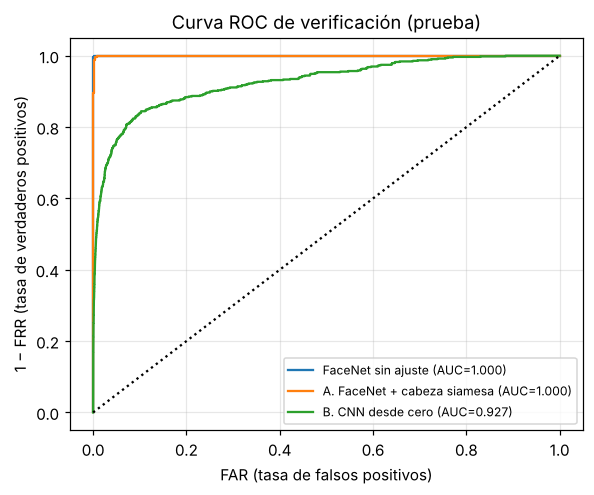

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.6))
for name, (fpr, tpr) in rocs.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC={ver_df.loc[name, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k:"); ax.set_xlabel("FAR (tasa de falsos positivos)"); ax.set_ylabel("1 − FRR (tasa de verdaderos positivos)")
ax.set_title("Curva ROC de verificación (prueba)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/03_roc.png", bbox_inches="tight"); plt.show()

## 2. Identificación one-shot y few-shot (1:N)
Para cada k ∈ {1, 3, 5} se eligen al azar k fotos de **train** por persona como galería; para las identidades *no vistas* se toman de su propio conjunto, que nunca se usó para entrenar. Todas las personas (vistas y no vistas) compiten a la vez en la galería. Cada imagen de consulta restante se asigna al prototipo más cercano. Se repite 30 veces con galerías distintas y se promedia.

In [7]:
def prototypes(e, idx_by_person):
    P = np.stack([e[i].mean(0) for i in idx_by_person.values()])
    return P / np.linalg.norm(P, axis=1, keepdims=True)

def identify(e_q, P, gal_names, thr=None):
    D = ((e_q[:, None, :] - P[None]) ** 2).sum(-1)
    j = D.argmin(1); dmin = D[np.arange(len(D)), j]
    pred = np.array(gal_names, dtype=object)[j]
    if thr is not None: pred = np.where(dmin <= thr, pred, "desconocido")
    return pred, dmin

rng = np.random.default_rng(SEED)
id_rows, last = [], {}
for k in [1, 3, 5]:
    for name, e in ENC.items():
        accs, acc_nv = [], []
        for rep in range(30):
            gal, query = {}, []
            for n in names:
                pool = np.where((labels_txt == n) & (nv if n in NO_VISTAS else tr))[0]
                if len(pool) < k + (1 if n in NO_VISTAS else 0): break
                g = rng.choice(pool, k, replace=False); gal[n] = g
                query += list(np.setdiff1d(np.where((labels_txt == n) & (te | nv))[0], g))
            else:
                query = np.array(query)
                pred, _ = identify(e[query], prototypes(e, gal), list(gal))
                accs.append((pred == labels_txt[query]).mean())
                m_nv = np.isin(labels_txt[query], NO_VISTAS)
                if m_nv.any(): acc_nv.append((pred[m_nv] == labels_txt[query][m_nv]).mean())
                last[(k, name)] = (query, pred)
                continue
            break
        if accs:
            id_rows.append({"k (fotos enroladas)": k, "encoder": name, "exactitud media": np.mean(accs), "desv.": np.std(accs),
                            "exactitud identidades no vistas": np.mean(acc_nv) if acc_nv else np.nan, "repeticiones": len(accs)})
id_df = pd.DataFrame(id_rows)
id_df.round(4)

,k (fotos enroladas),encoder,exactitud media,desv.,exactitud identidades no vistas,repeticiones
0,1,FaceNet sin ajuste,0.9994,0.0016,0.9996,30
1,1,A. FaceNet + cabeza siamesa,0.9894,0.0094,0.9752,30
2,1,B. CNN desde cero,0.7476,0.0220,0.5830,30
3,3,FaceNet sin ajuste,1.0000,0.0000,1.0000,30
4,3,A. FaceNet + cabeza siamesa,0.9981,0.0044,0.9948,30
5,3,B. CNN desde cero,0.8272,0.0133,0.6629,30
6,5,FaceNet sin ajuste,1.0000,0.0000,1.0000,30
7,5,A. FaceNet + cabeza siamesa,1.0000,0.0000,1.0000,30
8,5,B. CNN desde cero,0.8575,0.0178,0.6873,30


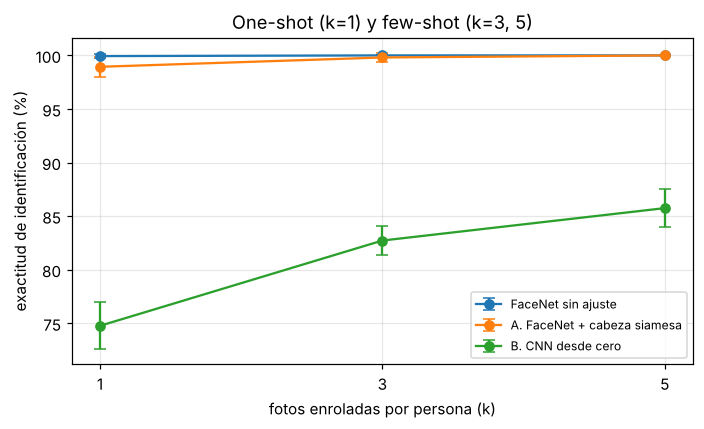

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, g in id_df.groupby("encoder", sort=False):
    ax.errorbar(g["k (fotos enroladas)"], 100 * g["exactitud media"], yerr=100 * g["desv."], marker="o", capsize=4, label=name)
ax.set_xticks([1, 3, 5]); ax.set_xlabel("fotos enroladas por persona (k)"); ax.set_ylabel("exactitud de identificación (%)")
ax.set_title("One-shot (k=1) y few-shot (k=3, 5)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/03_one_few_shot.png", bbox_inches="tight"); plt.show()

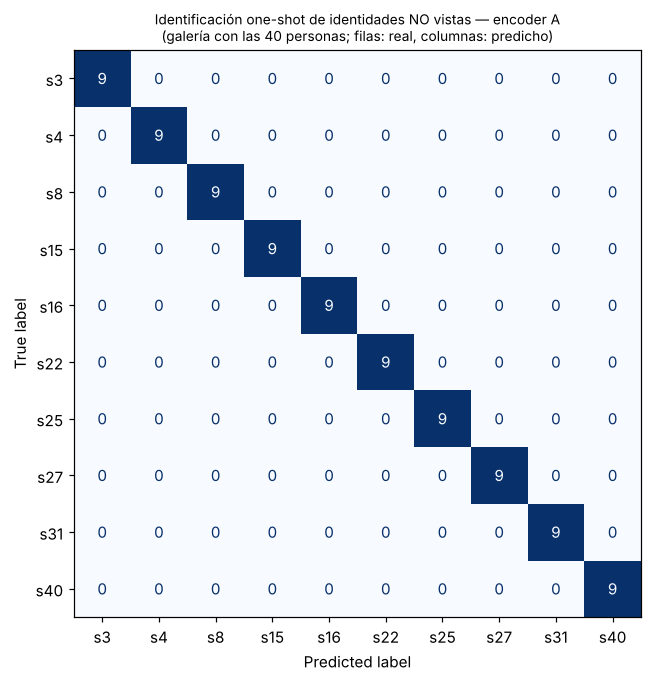

Aciertos one-shot en no vistas (última repetición): 90 de 90  (0 asignadas a personas fuera de las no vistas)


In [9]:
best_enc = "A. FaceNet + cabeza siamesa"
q, p = last[(1, best_enc)]
m = np.isin(labels_txt[q], NO_VISTAS)                      # consultas de identidades no vistas
cm = confusion_matrix(labels_txt[q][m], p[m], labels=NO_VISTAS)
fig, ax = plt.subplots(figsize=(7.5, 6.3))
ConfusionMatrixDisplay(cm, display_labels=NO_VISTAS).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Identificación one-shot de identidades NO vistas — encoder A\n(galería con las 40 personas; filas: real, columnas: predicho)", fontsize=9)
plt.tight_layout(); plt.savefig("figures/03_confusion_one_shot.png", bbox_inches="tight"); plt.show()
print(f"Aciertos one-shot en no vistas (última repetición): {np.trace(cm)} de {m.sum()}  "
      f"({(m.sum() - cm.sum())} asignadas a personas fuera de las no vistas)")

## 3. Zero-shot: identidad sin ninguna foto enrolada (conjunto abierto)
Se enrola a todas las personas **excepto** una (k = 3) y se presentan sus fotos al sistema. Como no existe ningún ejemplo de esa identidad, la respuesta correcta es **"desconocido"**: el sistema debe rechazarla porque su distancia al prototipo más cercano supera τ. Se repite dejando fuera a cada una de las 40 personas (5 galerías aleatorias por persona) y se mide:
* **Tasa de rechazo de desconocidos** (verdadero negativo en conjunto abierto).
* **Exactitud sobre los conocidos** con la misma regla de umbral.

In [10]:
open_rows = []
for name, e in ENC.items():
    thr = THR[name]
    rej, known_ok = [], []
    for out in names:
        for rep in range(5):
            gal = {}
            for n in names:
                if n == out: continue
                pool = np.where((labels_txt == n) & (nv if n in NO_VISTAS else tr))[0]
                gal[n] = rng.choice(pool, min(3, len(pool) - (1 if n in NO_VISTAS else 0)), replace=False)
            P = prototypes(e, gal)
            unk = np.where((labels_txt == out) & (te | nv))[0]
            pred_u, _ = identify(e[unk], P, list(gal), thr)
            rej.append((pred_u == "desconocido").mean())
            kn = np.setdiff1d(np.where((labels_txt != out) & (te | nv))[0], np.concatenate(list(gal.values())))
            pred_k, _ = identify(e[kn], P, list(gal), thr)
            known_ok.append((pred_k == labels_txt[kn]).mean())
    open_rows.append({"encoder": name, "umbral τ": thr, "rechazo de desconocidos": np.mean(rej), "exactitud en conocidos": np.mean(known_ok)})
open_df = pd.DataFrame(open_rows).set_index("encoder")
open_df.round(4)

,umbral τ,rechazo de desconocidos,exactitud en conocidos
encoder,,,
FaceNet sin ajuste,0.9747,0.9010,1.0000
A. FaceNet + cabeza siamesa,0.3123,0.9958,0.9462
B. CNN desde cero,0.1346,0.3085,0.8246


## 4. Demostración: función de reconocimiento
`reconocer()` recibe una imagen ya preprocesada, calcula su embedding con FaceNet + cabeza siamesa y la compara con la galería de las 40 personas (enrolamiento few-shot, k = 3). Se muestran 4 personas vistas en el entrenamiento y 4 no vistas (marcadas con *).

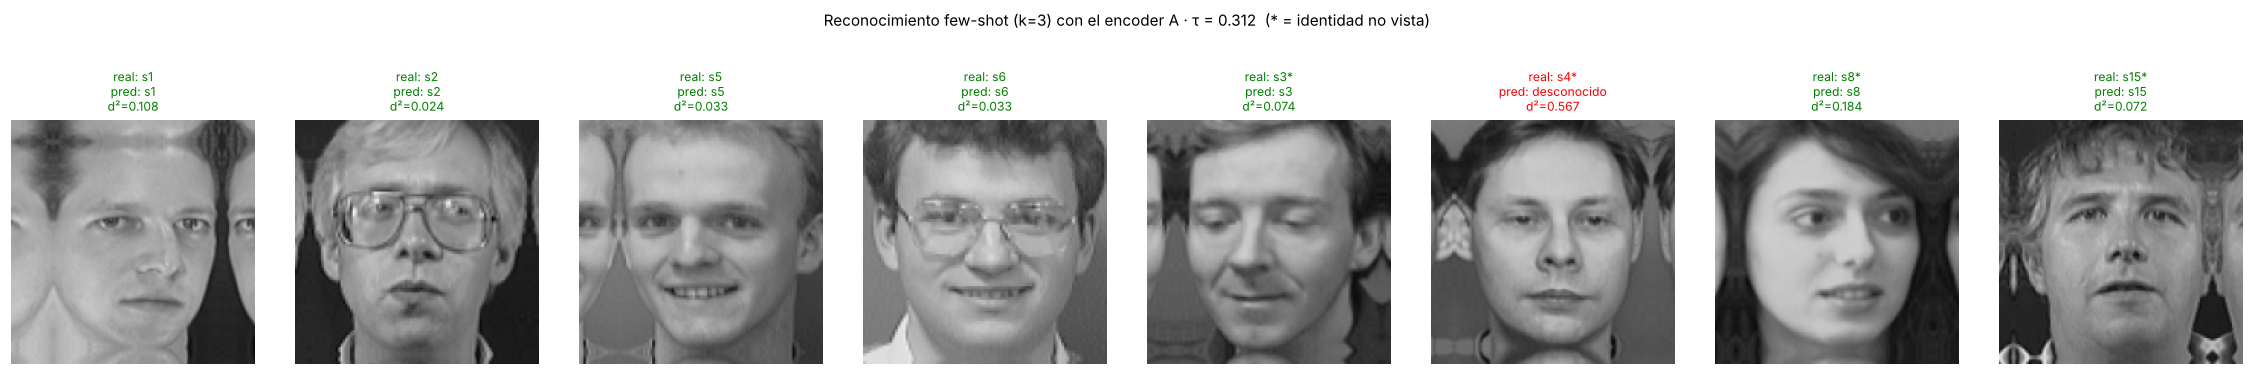

In [11]:
facenet = load_facenet()
head = keras.models.load_model("modelos/encoder_facenet_head.keras", custom_objects={"L2Normalize": L2Normalize})

gallery = {}
for n in names:
    pool = np.where((labels_txt == n) & (nv if n in NO_VISTAS else tr))[0]
    gallery[n] = pool[:3]
P_demo = prototypes(ENC[best_enc], gallery)

def reconocer(face_160, umbral=THR[best_enc]):
    """Rostro alineado 160x160 RGB -> (nombre o 'desconocido', distancia al prototipo más cercano)."""
    e = head.predict(facenet.predict(standardize(face_160[None]), verbose=0), verbose=0)
    pred, dist = identify(e, P_demo, list(gallery), umbral)
    return pred[0], float(dist[0])

demo_names = [n for n in names if n not in NO_VISTAS][:4] + NO_VISTAS[:4]
demo_q = [np.setdiff1d(np.where((labels_txt == n) & (te | nv))[0], gallery[n])[0] for n in demo_names]
fig, axes = plt.subplots(1, len(demo_q), figsize=(2.6 * len(demo_q), 3.0))
for a, i in zip(np.atleast_1d(axes), demo_q):
    who, dist = reconocer(faces[i])
    a.imshow(show(faces[i])); a.axis("off")
    a.set_title(f"real: {labels_txt[i]}{'*' if labels_txt[i] in NO_VISTAS else ''}\npred: {who}\nd²={dist:.3f}", fontsize=8, color="green" if who == labels_txt[i] else "red")
plt.suptitle(f"Reconocimiento few-shot (k=3) con el encoder A · τ = {THR[best_enc]:.3f}  (* = identidad no vista)", fontsize=10, y=1.12)
plt.tight_layout(); plt.savefig("figures/03_demo_reconocimiento.png", bbox_inches="tight"); plt.show()

### Comparación de pares
Matriz de distancias entre dos fotos **distintas** de cada identidad no vista (encoder A): la diagonal compara a la misma persona; fuera de ella, personas diferentes.

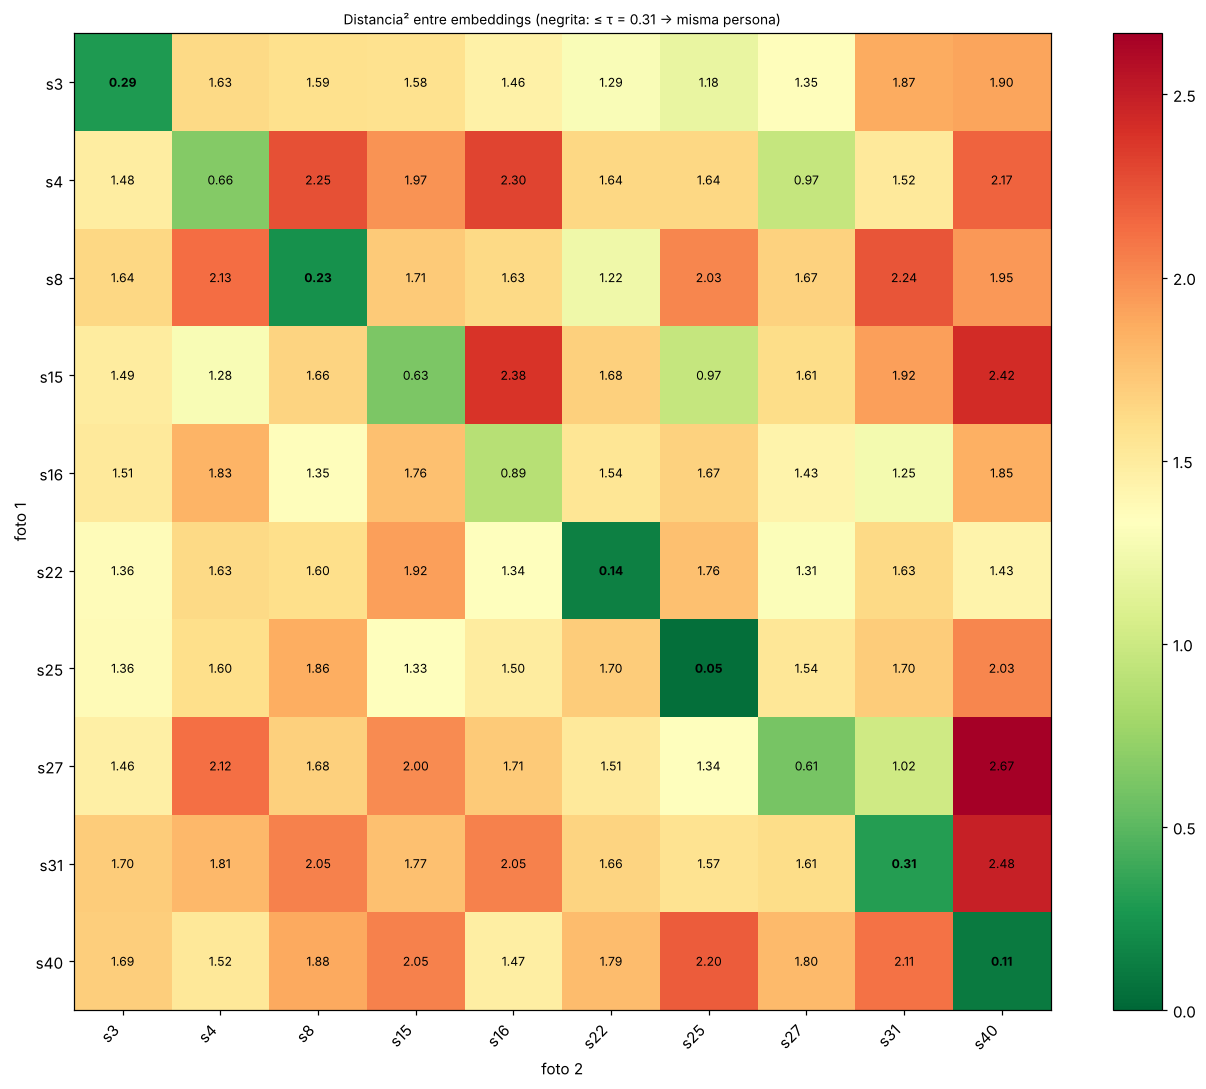

In [12]:
eA = ENC[best_enc]
sel1 = [np.where((labels_txt == n) & nv)[0][0] for n in NO_VISTAS]
sel2 = [np.where((labels_txt == n) & nv)[0][-1] for n in NO_VISTAS]
Dm = ((eA[sel1][:, None] - eA[sel2][None]) ** 2).sum(-1)
fig, ax = plt.subplots(figsize=(1.0 * len(NO_VISTAS) + 2, 0.9 * len(NO_VISTAS) + 1))
im = ax.imshow(Dm, cmap="RdYlGn_r", vmin=0, vmax=max(2.0, Dm.max()))
for i in range(len(NO_VISTAS)):
    for j in range(len(NO_VISTAS)):
        ax.text(j, i, f"{Dm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if Dm[i, j] <= THR[best_enc] else "normal")
ax.set_xticks(range(len(NO_VISTAS))); ax.set_xticklabels(NO_VISTAS, rotation=45, ha="right"); ax.set_yticks(range(len(NO_VISTAS))); ax.set_yticklabels(NO_VISTAS)
ax.set_xlabel("foto 2"); ax.set_ylabel("foto 1"); ax.set_title(f"Distancia² entre embeddings (negrita: ≤ τ = {THR[best_enc]:.2f} → misma persona)", fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.savefig("figures/03_matriz_distancias.png", bbox_inches="tight"); plt.show()

In [13]:
res = {"umbrales": THR, "verificacion": ver_df.reset_index().to_dict("records"), "identificacion": id_df.to_dict("records"),
       "conjunto_abierto": open_df.reset_index().to_dict("records"), "matriz_distancias": Dm.tolist(), "personas": names, "no_vistas": NO_VISTAS}
json.dump(res, open("results/03_pruebas.json", "w"), indent=2, ensure_ascii=False, default=float)

## 5. Análisis de resultados
* **Verificación (identidades vistas y no vistas, 24 090 pares).** FaceNet sin ajuste: AUC 1.000, EER 0.13 %, exactitud 99.8 %. Encoder A: AUC 0.9997 y EER 0.42 %, pero su umbral elegido en train (τ = 0.31) resultó demasiado estricto en prueba: FAR 0.03 % y **FRR 20.6 %**. Encoder B: AUC 0.927, EER 14.1 %.
* **One-shot / few-shot (40 personas en la galería).** FaceNet: 99.9 % con una sola foto; A: 98.9 % (k=1) → 100 % (k=5); B: 74.8 % (k=1) → 82.7 % (k=3) → 85.8 % (k=5). Promediar más fotos de enrolamiento mejora y estabiliza la identificación, sobre todo en el encoder más débil.
* **Zero-shot – identidades no vistas.** Con una foto de enrolamiento, A identifica correctamente el 97.5 % de las consultas de las 10 personas que nunca vio (100 % con k=5); B el 58.3 %. La red aprendió una métrica que generaliza a personas nuevas.
* **Zero-shot – personas no registradas (conjunto abierto).** A rechaza como «desconocido» el 99.6 % de las fotos de personas no enroladas, a costa de reconocer el 94.6 % de los conocidos; FaceNet rechaza el 90.1 % y acierta el 100 % de los conocidos; B sólo rechaza el 30.9 %. El umbral τ fija el compromiso entre seguridad (FAR) y comodidad (FRR).
* **Lección principal:** el umbral debe elegirse con datos que representen la operación real (un conjunto de validación con identidades no vistas). Elegirlo con pares de entrenamiento, que el modelo ya compactó, lo vuelve demasiado estricto.